In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/raw")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

visits = pd.read_csv(DATA / "air_visit_data.csv", parse_dates=["visit_date"])

count    252108.0
mean         21.0
std          16.8
min           1.0
50%          17.0
90%          43.0
99%          73.0
99.9%       115.0
max         877.0
Name: visitors, dtype: float64
skew raw: 3.31
skew log1p: -0.45


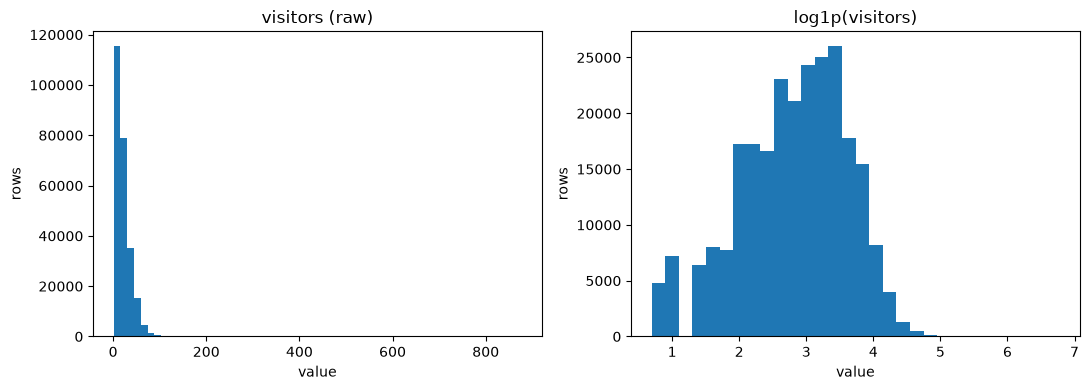

In [2]:
v = visits["visitors"]
print(v.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1))
print("skew raw:", round(v.skew(), 2))
print("skew log1p:", round(np.log1p(v).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(v, bins=60)
axes[0].set_title("visitors (raw)")
axes[1].hist(np.log1p(v), bins=30)
axes[1].set_title("log1p(visitors)")
for ax in axes:
    ax.set_xlabel("value")
    ax.set_ylabel("rows")
fig.tight_layout()
fig.savefig(FIG / "visitors_distribution.png", dpi=120)
plt.show()

In [3]:
print(visits.nlargest(10, "visitors"))

top = visits.loc[visits["visitors"].idxmax()]
s = visits[visits["air_store_id"] == top["air_store_id"]]
print(s["visitors"].describe().round(1))

# 3 days before and after the maximum
near = s[s["visit_date"].between(top["visit_date"] - pd.Timedelta(days=3),
                                 top["visit_date"] + pd.Timedelta(days=3))]
print(near)

q1, q3 = v.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("IQR upper fence:", upper, "| rows above:", (v > upper).sum())

lv = np.log1p(v)
lq1, lq3 = lv.quantile([0.25, 0.75])
lupper = lq3 + 1.5 * (lq3 - lq1)
print("log-scale rows above fence:", (lv > lupper).sum())

                air_store_id visit_date  visitors
85314   air_cfdeb326418194ff 2017-03-08       877
214825  air_8c3175aa5e4fc569 2017-04-18       777
72836   air_f2985de32bb792e0 2016-07-10       675
172123  air_eca5e0064dc9314a 2016-08-30       627
143894  air_43d577e0c9460e64 2016-01-24       514
167504  air_9828505fefc77d75 2016-11-19       409
147739  air_e42bdc3377d1eee7 2016-12-14       372
151243  air_cb083b4789a8d3a2 2016-01-14       369
141539  air_07bb665f9cdfbdfb 2016-08-07       351
200611  air_c6aa2efba0ffc8eb 2017-01-23       348
count    407.0
mean      17.1
std       43.8
min        1.0
25%        6.0
50%       15.0
75%       22.0
max      877.0
Name: visitors, dtype: float64
               air_store_id visit_date  visitors
85312  air_cfdeb326418194ff 2017-03-06         4
85313  air_cfdeb326418194ff 2017-03-07        11
85314  air_cfdeb326418194ff 2017-03-08       877
85315  air_cfdeb326418194ff 2017-03-09        17
85316  air_cfdeb326418194ff 2017-03-10        11
85317

In [4]:
top10 = visits.nlargest(10, "visitors").copy()
med = visits.groupby("air_store_id")["visitors"].median()
top10["store_median"] = top10["air_store_id"].map(med)
top10["ratio"] = (top10["visitors"] / top10["store_median"]).round(1)
print(top10)

# Are the 72 log-scale outliers spread out or concentrated in a few stores?
out72 = visits[lv > lupper]
print(out72["air_store_id"].value_counts().head(10))
print("stores involved:", out72["air_store_id"].nunique())

                air_store_id visit_date  visitors  store_median  ratio
85314   air_cfdeb326418194ff 2017-03-08       877          15.0   58.5
214825  air_8c3175aa5e4fc569 2017-04-18       777          29.0   26.8
72836   air_f2985de32bb792e0 2016-07-10       675          29.0   23.3
172123  air_eca5e0064dc9314a 2016-08-30       627          29.0   21.6
143894  air_43d577e0c9460e64 2016-01-24       514          31.0   16.6
167504  air_9828505fefc77d75 2016-11-19       409          15.0   27.3
147739  air_e42bdc3377d1eee7 2016-12-14       372          20.0   18.6
151243  air_cb083b4789a8d3a2 2016-01-14       369          26.0   14.2
141539  air_07bb665f9cdfbdfb 2016-08-07       351          28.0   12.5
200611  air_c6aa2efba0ffc8eb 2017-01-23       348          23.5   14.8
air_store_id
air_7514d90009613cd6    8
air_746211c0b532e8aa    4
air_df554c4527a1cfe6    3
air_eca5e0064dc9314a    3
air_1c0b150f9e696a5f    2
air_8f13ef0f5e8c64dd    2
air_b23d0f519291247d    2
air_d98380a4aeb0290b    

**Outlier policy (for now): keep all rows.**
Reason: it is not clear whether the extreme values are data errors or real events (for example a large group booking). The target will be log1p(visitors), which already limits their influence.
Revisit after: the first tuned model, during error analysis, to see whether the largest errors come from these rows.

In [5]:
s7 = visits[visits["air_store_id"] == "air_7514d90009613cd6"]
print(s7["visitors"].describe().round(1))
print(s7[s7["visitors"] > np.expm1(lupper)].sort_values("visit_date"))

count    231.0
mean      45.3
std       46.6
min        1.0
25%       11.0
50%       29.0
75%       57.5
max      239.0
Name: visitors, dtype: float64
              air_store_id visit_date  visitors
8740  air_7514d90009613cd6 2016-07-31       209
8835  air_7514d90009613cd6 2016-12-04       207
8840  air_7514d90009613cd6 2016-12-11       168
8845  air_7514d90009613cd6 2016-12-17       170
8846  air_7514d90009613cd6 2016-12-18       239
8855  air_7514d90009613cd6 2016-12-29       168
8857  air_7514d90009613cd6 2016-12-31       181
8908  air_7514d90009613cd6 2017-03-12       216


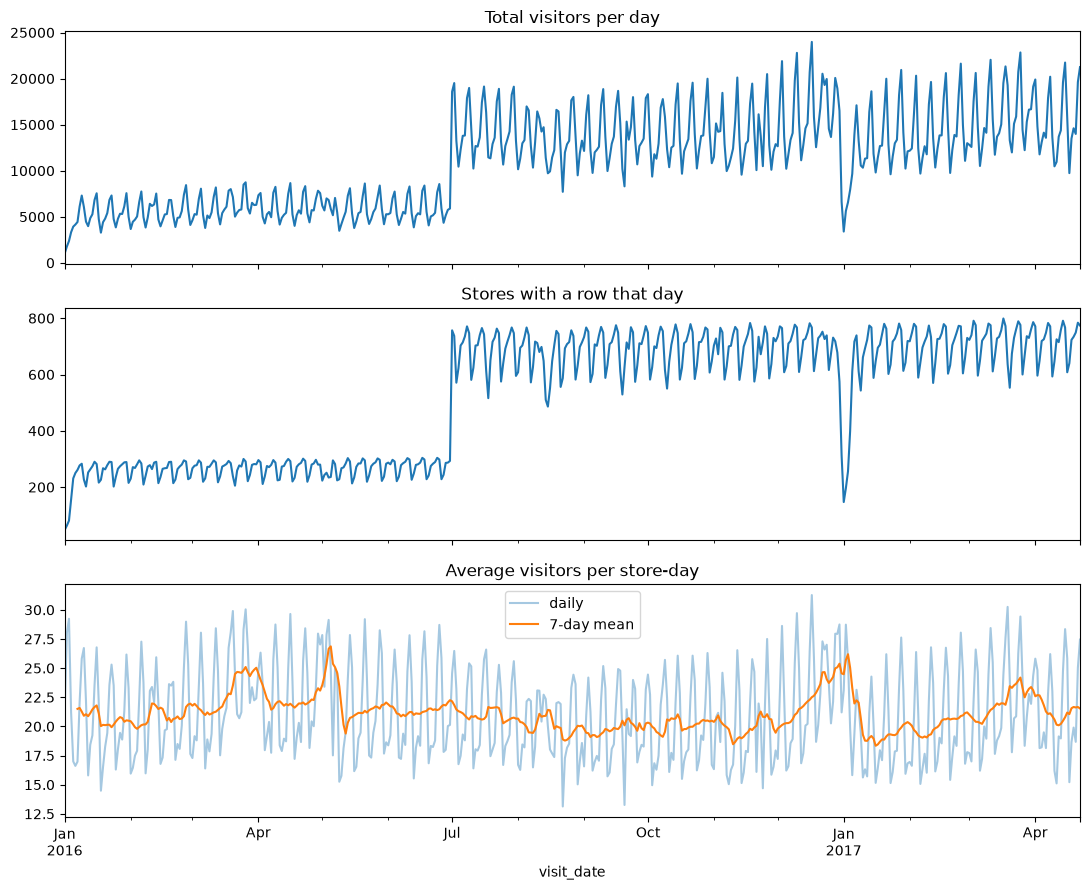

In [6]:
daily = visits.groupby("visit_date").agg(
    total=("visitors", "sum"),
    stores=("air_store_id", "nunique"),
)
daily["avg_per_store"] = daily["total"] / daily["stores"]

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
daily["total"].plot(ax=axes[0], title="Total visitors per day")
daily["stores"].plot(ax=axes[1], title="Stores with a row that day")
daily["avg_per_store"].plot(ax=axes[2], alpha=0.4, label="daily")
daily["avg_per_store"].rolling(7).mean().plot(ax=axes[2], label="7-day mean")
axes[2].set_title("Average visitors per store-day")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG / "daily_series.png", dpi=120)
plt.show()

count    829.0
mean      21.2
std       11.8
min        1.2
25%       11.8
50%       19.2
75%       28.6
max      115.5
Name: mean, dtype: float64
                      mean  median  std  count   cv
air_store_id                                       
air_a21ffca0bea1661a   1.2     1.0  0.8    160  0.7
air_bbe1c1a47e09f161   2.6     1.0  4.1    220  1.5
air_fdcfef8bd859f650   3.6     3.0  2.3    174  0.7
                       mean  median   std  count   cv
air_store_id                                         
air_9c6787aa03a45586   76.5    83.0  36.8     70  0.5
air_900d755ebd2f7bbd   82.2    83.5  29.2     20  0.4
air_1c0b150f9e696a5f  115.5   115.0  23.2     51  0.2


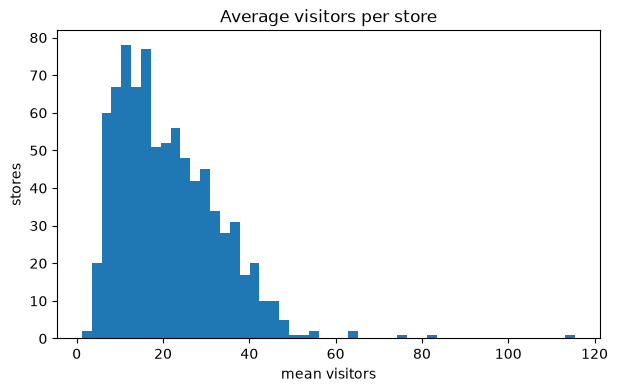

In [7]:
per_store = visits.groupby("air_store_id")["visitors"].agg(["mean", "median", "std", "count"])
per_store["cv"] = per_store["std"] / per_store["mean"]   # relative variability

print(per_store["mean"].describe().round(1))
print(per_store.sort_values("mean").head(3).round(1))
print(per_store.sort_values("mean").tail(3).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(per_store["mean"], bins=50)
ax.set_title("Average visitors per store")
ax.set_xlabel("mean visitors")
ax.set_ylabel("stores")
fig.savefig(FIG / "store_means.png", dpi=120)
plt.show()

In [8]:
# Where exactly does the store count jump?
s = daily["stores"]
jump = s.diff().idxmax()
print("Biggest one-day jump:", jump.date(), s.shift(1).loc[jump], "->", s.loc[jump])

# New Year dip
print(daily.loc["2016-12-25":"2017-01-08", ["stores", "avg_per_store"]].round(1))

# Golden Week 2016 vs most of April 2016 (rough: weekday mix is not identical)
print("Golden Week:", daily.loc["2016-04-29":"2016-05-08", "avg_per_store"].mean().round(1))
print("April 1-21: ", daily.loc["2016-04-01":"2016-04-21", "avg_per_store"].mean().round(1))

Biggest one-day jump: 2016-07-01 293.0 -> 757
            stores  avg_per_store
visit_date                       
2016-12-25     616           23.6
2016-12-26     674           20.3
2016-12-27     731           22.1
2016-12-28     718           28.0
2016-12-29     678           27.9
2016-12-30     574           28.7
2016-12-31     312           21.2
2017-01-01     147           23.1
2017-01-02     196           28.7
2017-01-03     256           25.7
2017-01-04     399           19.9
2017-01-05     611           15.8
2017-01-06     717           19.4
2017-01-07     739           23.1
2017-01-08     611           21.7
Golden Week: 25.5
April 1-21:  21.8


## Key findings
1. Distribution: visitors is right-skewed (median 17, mean 21.0, 99% = 73, 99.9% = 115, max 877, a single row). Skew is 3.31 on the raw scale and -0.45 after log1p, so the target will be log1p(visitors).
2. Outliers: a raw IQR rule flags 6,959 rows (2.8%), but it over-flags because the data is skewed. On the log1p scale only 72 rows in 50 stores are flagged. The top 10 values are 12.5x to 58.5x their own store's median.
3. Time trend: On 2016-07-01 the number of stores with a row jumps in one day from 293 to 757 (about 2.6x), and total daily visitors rise by a similar factor, while the average per store-day stays flat (the 7-day mean stays between about 18 and 26). So the jump comes from more stores in the data, not from higher demand. A one-day jump looks like a change in the data source. In early January 2017 the store count falls from 731 (2016-12-27) to 147 (2017-01-01), consistent with restaurants closing for New Year. Golden Week 2016 averaged 25.5 visitors per store-day vs 21.8 in early April (a rough comparison, since the weekday mix differs).
4. Stores: store means range from 1.2 to 115.5 (median store ), so store identity matters a lot. Stores with few rows (for example air_900d755ebd2f7bbd with 20 rows) are hard to estimate (cold start).5. Decisions so far: keep all rows (no outliers removed yet; revisit after the first tuned model); target = log1p(visitors); do not fill missing rows with 0; validation = last 39 days of the training data.

**MAE vs RMSLE:** for 10 -> 20 the MAE error is 10 and the log error is 0.647. For 100 -> 50 the MAE error is 50 and the log error is 0.683. MAE says the second mistake is 5 times bigger, but RMSLE treats both as about the same, because it measures the error on a log scale, i.e. relative to the size of the value (a factor of 2 in both cases). So MAE is dominated by large stores, while RMSLE gives small and large stores a more equal weight. This matters here because store means range from 1.2 to 115.5.